# FPCA-SBI pipeline

Stages: simulate → generate light curves → fit → merge (processing) → prepare features → train SBI → bias/uncertainty.

All file paths come from `config.py` via `AnalysisConfig(split=...)`.

## 1. Simulated parameters

In [1]:
from config import config
from simulate import simulate

theory_df = simulate(config.sim_gen)
theory_df.to_csv(config.sim_gen.output_path, index=False)
theory_df.head()

n_cosmo = theory_df["cosmo_id"].nunique()
per_cosmo = theory_df.groupby("cosmo_id").size()
print(f"Sim: {n_cosmo} cosmologies, {per_cosmo.min()}–{per_cosmo.max()} SNe/cosmo, {len(theory_df)} SNe total")

simulating cosmologies: 100%|██████████| 500/500 [00:05<00:00, 98.60it/s] 


Sim: 500 cosmologies, 20–20 SNe/cosmo, 10000 SNe total


## 2. Generate light curves

In [2]:
from lc_gen import run as run_gen
from config import config

run_gen(config.lightcurves)

import glob, os, re
import pandas as pd

files = glob.glob(os.path.join(config.lightcurves.output_dir, "*.csv"))
ids = [tuple(map(int, re.findall(r"\d+", os.path.basename(f))[:2])) for f in files]
lc_ids = pd.DataFrame(ids, columns=["cosmo_id", "sn_id"])
per_cosmo = lc_ids.groupby("cosmo_id").size()
print(f"LC gen: {lc_ids['cosmo_id'].nunique()} cosmologies, "
      f"{per_cosmo.min()}–{per_cosmo.max()} SNe/cosmo, {len(lc_ids)} LCs total")

Reading input file: data/train_params_theory.csv
Loaded 10000 SNe across 500 cosmologies
1%
2%
3%
4%
5%
6%
7%
8%
9%
10%
11%
12%
13%
14%
15%
16%
17%
18%
19%
20%
21%
22%
23%
24%
25%
26%
27%
28%
29%
30%
31%
32%
33%
34%
35%
36%
37%
38%
39%
40%
41%
42%
43%
44%
45%
46%
47%
48%
49%
50%
51%
52%
53%
54%
55%
56%
57%
58%
59%
60%
61%
62%
63%
64%
65%
66%
67%
68%
69%
70%
71%
72%
73%
74%
75%
76%
77%
78%
79%
80%
81%
82%
83%
84%
85%
86%
87%
88%
89%
90%
91%
92%
93%
94%
95%
96%
97%
98%
99%
100%
Done. Saved 5476/10000 light curves to data/lc_train
LC gen: 500 cosmologies, 2–19 SNe/cosmo, 5476 LCs total


## 3. Fit light curves

In [3]:
from lc_fit import run as run_fitting
from config import config

run_fitting(config.fitting)

import pandas as pd

fit = pd.read_csv(config.fitting.raw_csv)
sn = fit[["cosmo_id", "sn_id"]].drop_duplicates()
per_cosmo = sn.groupby("cosmo_id").size()
print(f"Fit: {sn['cosmo_id'].nunique()} cosmologies, "
      f"{per_cosmo.min()}–{per_cosmo.max()} SNe/cosmo, {len(sn)} SNe total, {len(fit)} band-rows")

Found 5476 light curve files in data/lc_train


fitting light curves: 1498it [01:11, 21.00it/s]

Done. Fit 1494 SNe (3851 band-rows) -> data/train_fit_raw.csv
Fit: 498 cosmologies, 3–3 SNe/cosmo, 1494 SNe total, 3851 band-rows


## 4. Merge bands (one row per SN, NaN for missing bands)

In [4]:
from processing import run as run_processing
from config import config

merged = run_processing(config.fitting, config.fitting.raw_csv, config.processing.merged_csv)
merged.head()

Done. Merged 1494 SNe across 3 bands -> data/train_merged.csv


,cosmo_id,sn_id,omega_m,omega_lambda,redshift,mag_lsstr,lsstr_a1,lsstr_a2,err_mag_lsstr,err_a1_lsstr,...,err_a1_lssti,err_a2_lssti,chi_dof_lssti,mag_lsstz,lsstz_a1,lsstz_a2,err_mag_lsstz,err_a1_lsstz,err_a2_lsstz,chi_dof_lsstz
0,0,2,0.548814,0.715189,0.941466,NaN,NaN,NaN,NaN,NaN,...,0.368644,0.180852,0.807641,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,0,7,0.548814,0.715189,0.401879,21.782406,-4.180515,0.689083,0.009744,0.220007,...,0.162491,0.087161,2.174640,22.037963,0.953457,0.123766,0.026577,0.190381,0.106287,0.756951
2,0,8,0.548814,0.715189,0.561764,22.973145,-6.951085,0.031648,0.021788,0.582788,...,0.261227,0.123139,2.140939,23.077990,-0.092386,0.347533,0.060611,0.252099,0.130059,1.134577
3,1,0,0.572252,0.223082,1.213547,NaN,NaN,NaN,NaN,NaN,...,0.451051,0.222686,0.712288,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,1,1,0.572252,0.223082,0.829828,NaN,NaN,NaN,NaN,NaN,...,0.336221,0.164005,0.168189,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 5. Prepare features (bands chosen from train, NaN → 0, same columns for train and test)

In [5]:
from prepare_features import build_train_test_features
from config import config, AnalysisConfig, PARAM_COLS

# Needs both splits (run stages 1-4 once with split="train" and once with split="test" first)
train_cfg = AnalysisConfig(split="train")
test_cfg  = AnalysisConfig(split="test")

train_df, test_df, feature_cols, available_bands = build_train_test_features(
    train_cfg.processing.merged_csv,
    test_cfg.processing.merged_csv,
    list(config.fitting.bands),
    PARAM_COLS,
    train_cfg.prepare_features.features_csv,
    test_cfg.prepare_features.features_csv,
    config.fitting.max_sn_per_cosmo,
)
print("Number of features:", len(feature_cols))
train_df.head()

Bands with data in training set: ['lsstr', 'lssti', 'lsstz']
Wrote feature matrices (498 train sets, 50 test sets, 30 features each) -> data/train_features.csv, data/test_features.csv
Number of features: 30


,cosmo_id,omega_m,omega_lambda,redshift_0,mag_lsstr_0,lsstr_a1_0,lsstr_a2_0,mag_lssti_0,lssti_a1_0,lssti_a2_0,...,redshift_2,mag_lsstr_2,lsstr_a1_2,lsstr_a2_2,mag_lssti_2,lssti_a1_2,lssti_a2_2,mag_lsstz_2,lsstz_a1_2,lsstz_a2_2
0,0,0.548814,0.715189,0.401879,21.782406,-4.180515,0.689083,21.908018,-0.380052,0.550266,...,0.941466,0.000000,0.00000,0.000000,24.582391,-6.823467,1.040662,0.00000,0.000000,0.000000
1,1,0.572252,0.223082,0.829828,0.000000,0.000000,0.000000,24.149917,-5.578170,0.926592,...,1.213547,0.000000,0.00000,0.000000,24.593629,-9.845610,1.339060,0.00000,0.000000,0.000000
2,2,0.663078,0.263322,0.671686,23.339648,-7.006418,0.504638,23.035458,-3.934365,0.654443,...,1.256542,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000,23.56117,-3.654827,1.907117
3,3,0.727044,0.270328,0.779980,24.296840,-7.707819,0.601977,23.267714,-5.010250,0.891339,...,1.007696,24.689564,-9.12034,0.614237,23.406167,-7.494588,1.159434,23.28687,-2.323327,1.401827
4,4,0.638762,0.490305,0.724942,23.525968,-6.791207,0.706561,23.005930,-4.324714,0.914919,...,0.923342,0.000000,0.00000,0.000000,24.097558,-6.622063,1.019527,0.00000,0.000000,0.000000


## 6. Train SBI and evaluate on the test set

498 training SNe, 30 feature columns: ['redshift_0', 'mag_lsstr_0', 'lsstr_a1_0', 'lsstr_a2_0', 'mag_lssti_0', 'lssti_a1_0', 'lssti_a2_0', 'mag_lsstz_0', 'lsstz_a1_0', 'lsstz_a2_0', 'redshift_1', 'mag_lsstr_1', 'lsstr_a1_1', 'lsstr_a2_1', 'mag_lssti_1', 'lssti_a1_1', 'lssti_a2_1', 'mag_lsstz_1', 'lsstz_a1_1', 'lsstz_a2_1', 'redshift_2', 'mag_lsstr_2', 'lsstr_a1_2', 'lsstr_a2_2', 'mag_lssti_2', 'lssti_a1_2', 'lssti_a2_2', 'mag_lsstz_2', 'lsstz_a1_2', 'lsstz_a2_2']
x.shape torch.Size([498, 30])
 Neural network successfully converged after 56 epochs.

  0%|          | 0/100000 [00:00<?, ?it/s]

true_values [0.3143300507240683, 0.7219543613905867]
omega_m:
  Median = 0.4887
  1-sigma (68%) lower = 0.2359, upper = 0.7423
  2-sigma (95%) lower = 0.0593, upper = 0.9333
omega_lambda:
  Median = 0.4812
  1-sigma (68%) lower = 0.2376, upper = 0.7308
  2-sigma (95%) lower = 0.0618, upper = 0.9236


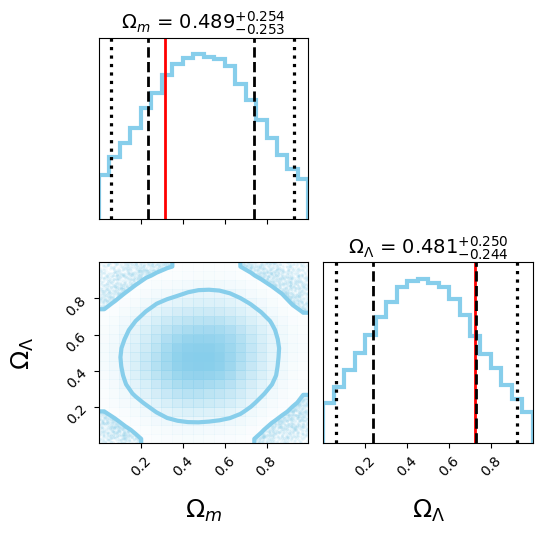

In [6]:
from single_run import run as run_sbi_training
import single_run
from config import config

test_index=43
posterior, samples = run_sbi_training(config.sbi.train_features_csv,
                                      config.sbi.test_features_csv, test_index=test_index)

## 7. Bias and uncertainty

--- seed 0 (1/3) ---
x.shape torch.Size([498, 30])
 Neural network successfully converged after 64 epochs.--- seed 20 (2/3) ---
x.shape torch.Size([498, 30])
 Neural network successfully converged after 66 epochs.--- seed 42 (3/3) ---
x.shape torch.Size([498, 30])
 Neural network successfully converged after 56 epochs.Saved 50 test sets (3 seeds) -> results/bias_unc.csv
Bias/sigma and 1-sigma over 50 test sets:
                       median   mean
omega_m_err_min         0.485  0.503
omega_m_unc_min         0.244  0.247
omega_lambda_err_min   -0.468 -0.475
omega_lambda_unc_min    0.240  0.240
omega_m_err_med         0.558  0.565
omega_m_unc_med         0.245  0.247
omega_lambda_err_med   -0.587 -0.573
omega_lambda_unc_med    0.244  0.243
omega_m_err_mean        0.558  0.565
omega_m_unc_mean        0.245  0.247
omega_lambda_err_mean  -0.587 -0.573
omega_lambda_unc_mean   0.244  0.243
Saved figure -> figures/bias_unc.png


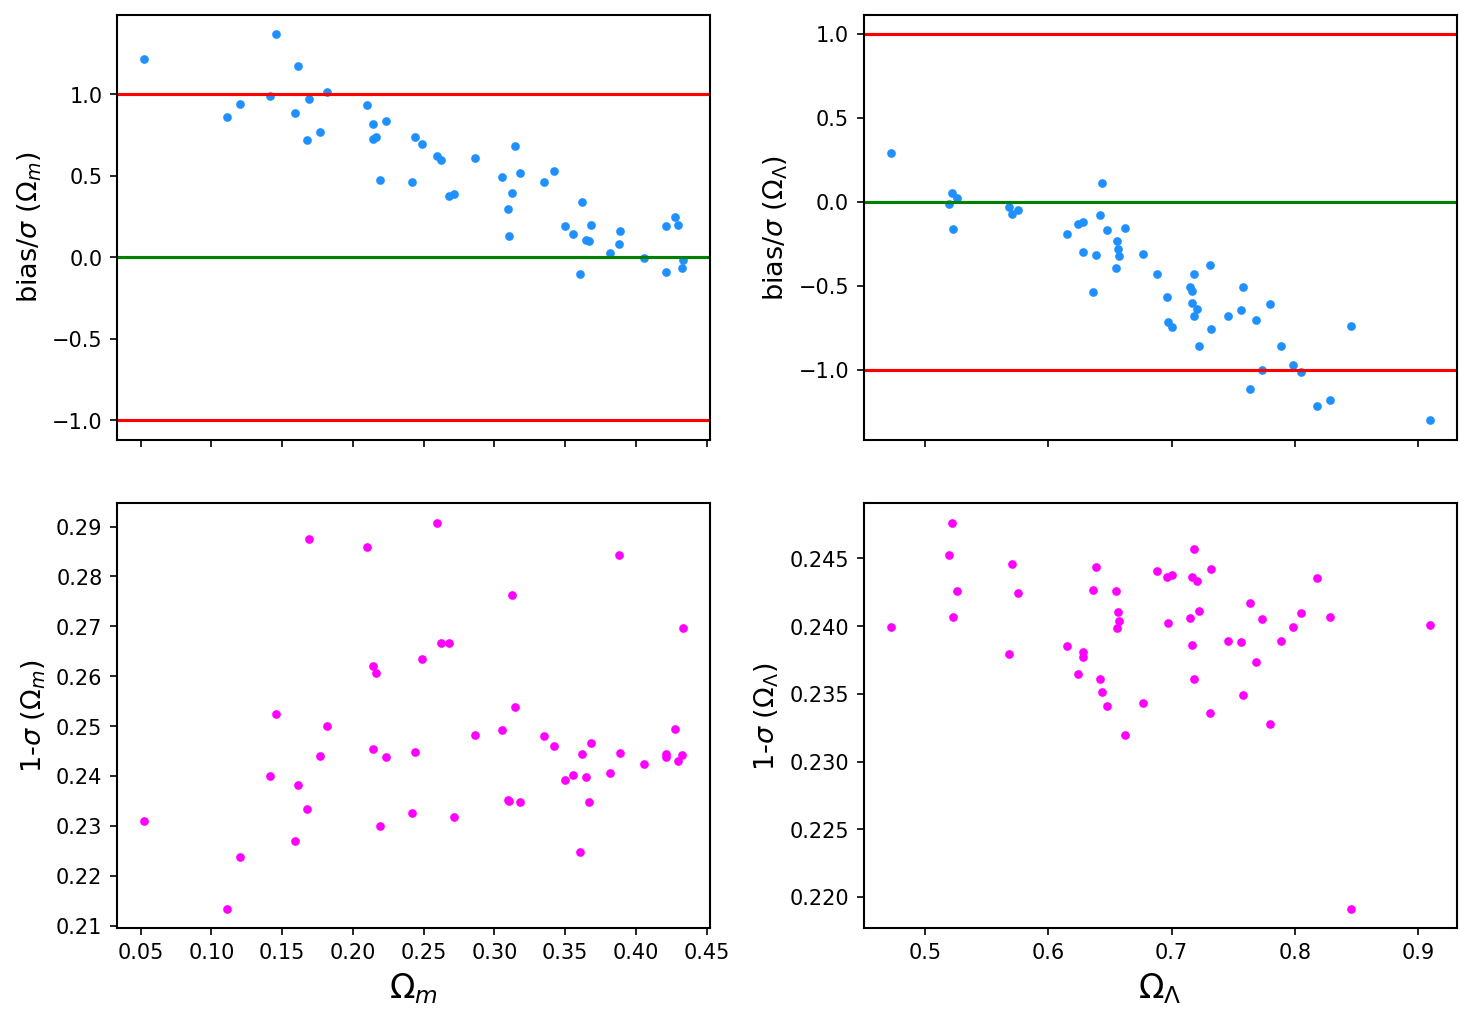

In [7]:
import pandas as pd
from config import config




from bias_unc import run_seeds, summary, plot_bias_unc

run_seeds()
summary()
plot_bias_unc()